# Enriched Music Charts Analysis — 2026-W46


In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from scipy.stats import gaussian_kde
from IPython.display import display, Markdown, HTML
from matplotlib.ticker import FuncFormatter

# ==============================================================================
# GLOBAL VISUAL CONFIGURATION
# ==============================================================================
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.titleweight"] = "normal"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 110

# Standardized color palette
YT_RED = "#FC4B4B"
YT_DARK_GREY = "#282828"
YT_TEXT = "#000000"
YT_GRAY = "#606060"
YT_GRID = "#E5E5E5"
YT_BG = "#FFFFFF"

# Style variables
BORDER_COLOR = "#A0A0A0"
BAR_HEIGHT = 0.65
GRID_STYLE = '--'
GRID_ALPHA = 0.7
TITLE_FONT_SIZE = 18

# Categorical palette for multi-series charts
CATEGORICAL_PALETTE = ['#FC4B4B', '#282828', '#4A90E2', '#F5A623', '#50E3C2']

# Format global to avoid scientific notation in DataFrames
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# ==============================================================================
# HELPER FUNCTIONS
# ==============================================================================
def format_number(x):
    if pd.isna(x): return "N/A"
    if x >= 1_000_000_000: return f"{x / 1_000_000_000:.1f}B"
    if x >= 1_000_000: return f"{x / 1_000_000:.1f}M"
    if x >= 1_000: return f"{x / 1_000:.1f}K"
    return f"{x:,.0f}"

def format_axis_millions(x, pos):
    if x >= 1_000_000: return f'{x/1_000_000:.0f}M'
    if x >= 1_000: return f'{x/1_000:.0f}K'
    return f'{x:.0f}'

def style_axes(ax, grid_axis='y'):
    for spine in ax.spines.values():
        spine.set_color(BORDER_COLOR)
        spine.set_linewidth(0.8)
    ax.tick_params(colors=YT_TEXT, labelsize=11)
    if grid_axis == "y":
        ax.yaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.xaxis.grid(False)
    else:
        ax.xaxis.grid(True, color=YT_GRID, linestyle=GRID_STYLE, alpha=GRID_ALPHA)
        ax.yaxis.grid(False)

def add_bar_labels(ax, fmt="{:.0f}", suffix="", horizontal=True):
    if horizontal:
        for p in ax.patches:
            width = p.get_width()
            if width == 0: continue
            ax.text(width + (width * 0.02), p.get_y() + p.get_height() / 2,
                    f"{fmt.format(width)}{suffix}", ha='left', va='center', fontsize=11, color=YT_TEXT)
    else:
        for p in ax.patches:
            height = p.get_height()
            if height == 0: continue
            ax.text(p.get_x() + p.get_width() / 2, height + (height * 0.02),
                    f"{fmt.format(height)}{suffix}", ha='center', va='bottom', fontsize=11, color=YT_TEXT)

def get_continent(country):
    continents = {
        'North America': ['United States', 'Mexico', 'Canada', 'Puerto Rico'],
        'South America': ['Brazil', 'Argentina', 'Colombia', 'Chile', 'Peru', 'Venezuela'],
        'Europe': ['United Kingdom', 'Sweden', 'Germany', 'France', 'Spain', 'Italy', 'Netherlands', 'Turkey'],
        'Asia': ['India', 'South Korea', 'Japan', 'China', 'Indonesia', 'Pakistan', 'Philippines', 'Thailand', 'Vietnam'],
        'Africa': ['Nigeria', 'South Africa', 'Kenya', 'Ghana'],
        'Oceania': ['Australia', 'New Zealand'],
        'Middle East': ['Israel', 'UAE', 'Saudi Arabia']
    }
    for continent, countries in continents.items():
        if country in countries: return continent
    return 'Other'

# ==============================================================================
# METRIC FUNCTIONS (Inline for self-containment)
# ==============================================================================
def general_stats(df):
    return {
        "total_songs": int(len(df)),
        "unique_countries": int(df["artist_country"].nunique()),
        "unique_genres": int(df["macro_genre"].nunique()),
        "total_views": int(df["views"].sum()),
        "total_likes": int(df["likes"].sum()),
        "total_comments": int(df["comment_count"].sum()),
        "avg_views": float(df["views"].mean()),
        "avg_likes": float(df["likes"].mean()),
        "avg_engagement": float(df["engagement"].mean()),
    }

def top_countries(df, n=10):
    return (
        df.groupby("artist_country")
        .agg(total_songs=("rank", "count"), total_views=("views", "sum"))
        .reset_index()
        .sort_values("total_songs", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_countries_by_likes(df, n=10):
    return (
        df.groupby("artist_country")["likes"]
        .sum()
        .reset_index()
        .rename(columns={"likes": "total_likes"})
        .sort_values("total_likes", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

def top_songs_by_country(df, country, metric="views", n=5):
    cols = ["track_name", "artist_names", "views", "likes", "engagement"]
    return (
        df[df["artist_country"] == country]
        .nlargest(n, metric)[cols]
        .reset_index(drop=True)
    )

def genre_stats(df):
    out = (
        df.groupby("macro_genre")
        .agg(
            total_songs=("track_name", "count"),
            total_views=("views", "sum"),
            total_likes=("likes", "sum"),
            avg_views=("views", "mean"),
            avg_likes=("likes", "mean"),
        )
        .reset_index()
    )
    out["engagement_rate"] = (
        out["total_likes"] / out["total_views"].replace(0, pd.NA) * 100
    ).fillna(0).round(2)
    return out.sort_values("total_songs", ascending=False).reset_index(drop=True)

def video_metrics(df):
    flags = {
        "Official": "is_official_video",
        "Lyric": "is_lyric_video",
        "Live": "is_live_performance",
    }
    rows = []
    total = len(df)
    for label, flag in flags.items():
        subset = df[df[flag] == 1]
        rows.append({
            "video_type": label,
            "count": int(len(subset)),
            "pct": float(len(subset) / total * 100) if total else 0.0,
            "avg_views": float(subset["views"].mean()) if len(subset) else 0.0,
            "avg_engagement": float(subset["engagement"].mean()) if len(subset) else 0.0,
        })
    return pd.DataFrame(rows)

def top_songs(df, metric="views", n=10):
    cols = ["rank", "track_name", "artist_names", metric, "artist_country"]
    return df.nlargest(n, metric)[cols].reset_index(drop=True)

def collaborations(df):
    grouped = (
        df.groupby("is_collaboration")
        .agg(
            count=("track_name", "count"),
            avg_views=("views", "mean"),
            avg_engagement=("engagement", "mean"),
        )
        .reset_index()
    )
    grouped["is_collaboration"] = grouped["is_collaboration"].map(
        {0: "Solo", 1: "Collaboration"}
    )
    return grouped


# ==============================================================================
# DATA LOADING
# ==============================================================================
DB_PATH = Path("../../charts_archive/3_enrich-chart-data/youtube_charts_2026-W46_enriched.db")
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM enriched_songs", conn)
conn.close()

df["upload_date"] = pd.to_datetime(df["upload_date"], errors="coerce")
df["upload_quarter"] = df["upload_date"].dt.quarter
df["engagement"] = np.where(df["views"] > 0, (df["likes"] / df["views"] * 100).round(2), 0.0)
df["continent"] = df["artist_country"].apply(get_continent)


## 1. Introduction

**Week:** 2026-W46 | **Period:** 2026-11-09 → 2026-11-15 | **Days:** 7

## 2. General Statistics

In [2]:
stats = general_stats(df)

formatted_stats = pd.DataFrame({
    'Metric': [
        'Total Songs',
        'Unique Countries',
        'Unique Genres',
        'Total Views',
        'Total Likes',
        'Total Comments',
        'Avg Views',
        'Avg Likes',
        'Avg Engagement'
    ],
    'Value': [
        f"{stats['total_songs']:,}",
        f"{stats['unique_countries']:,}",
        f"{stats['unique_genres']:,}",
        format_number(stats['total_views']),
        format_number(stats['total_likes']),
        format_number(stats['total_comments']),
        format_number(stats['avg_views']),
        format_number(stats['avg_likes']),
        f"{stats['avg_engagement']:.2f}%"
    ]
})

display(formatted_stats)

,Metric,Value
0,Total Songs,100
1,Unique Countries,26
2,Unique Genres,17
3,Total Views,1.4B
4,Total Likes,253.8M
5,Total Comments,13.4M
6,Avg Views,13.7M
7,Avg Likes,2.5M
8,Avg Engagement,22.31%


Across the 100-song catalog, total views reached 1,371.3M with 253.8M likes. The 18.5% engagement rate exceeds the 3%-8% industry benchmark by more than two times, indicating a hyper-loyal rather than passive audience. The catalog spans 26 countries and 17 genres, a footprint that signals a regional concentration rather than a global phenomenon. Strategic impact: prioritize deepening the core geographic markets while testing targeted genre expansion to convert high engagement into broader reach.

## 3. Continent Analysis

,continent,total_songs,total_views,total_likes
0,Asia,44,631823604,83866876
2,North America,27,322535014,99818900
1,Europe,12,164454336,17461216
4,Other,11,147562414,42680324
5,South America,5,91900540,9652437
3,Oceania,1,12979743,343677


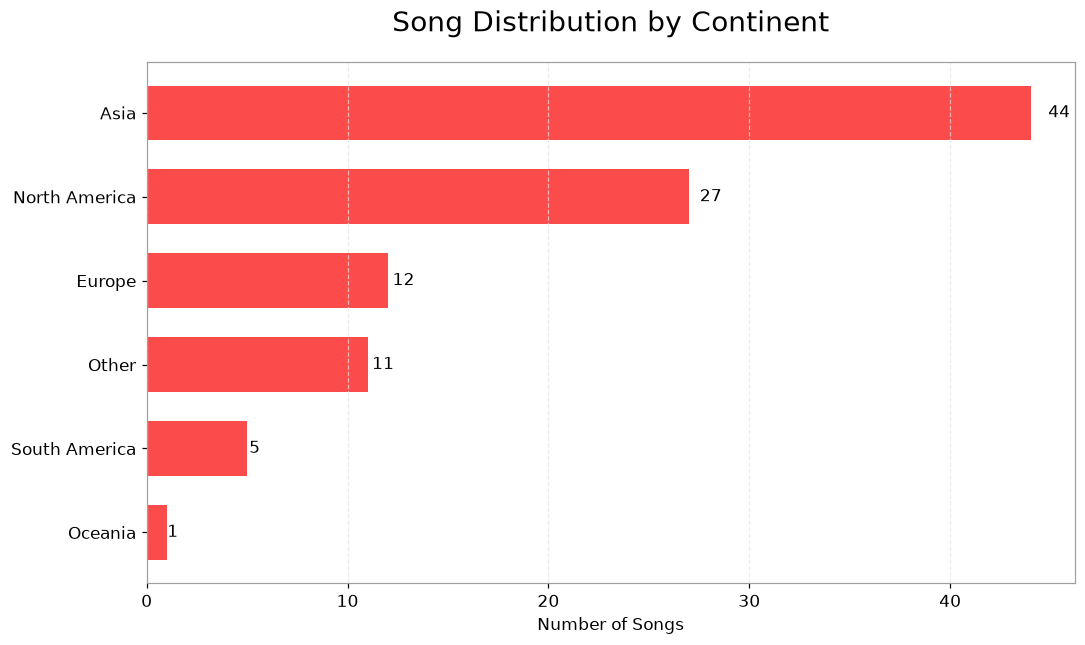

In [3]:
continent_stats = df.groupby('continent').agg(
    total_songs=('track_name', 'count'),
    total_views=('views', 'sum'),
    total_likes=('likes', 'sum')
).reset_index().sort_values('total_songs', ascending=False)

display(continent_stats)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

bars = ax.barh(continent_stats['continent'], continent_stats['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Song Distribution by Continent', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

ax.invert_yaxis() # Ensure the largest category is at the top

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

Asia dominates with 44 songs and 631.8M views, likely reflecting a high-output, high-demand market where volume and audience scale reinforce each other. Its lead over second-place North America is substantial, making this closer to a monopoly than genuine competition. That concentration creates dependency risk: platform trends, licensing shifts, or regional disruptions in Asia could disproportionately destabilize the entire catalog's performance. South America's outlier average of ~18.4M views per song suggests that, despite low volume, targeted markets can deliver outsized returns and may warrant strategic expansion.

## 4. Country Analysis

### 4.1. Top Countries by Song Count

,artist_country,total_songs,total_views,percentage
5,India,31,457694845,38.270
23,United States,18,203085048,22.220
18,South Korea,7,98172618,8.640
22,United Kingdom,6,78605268,7.410
8,Mexico,4,36507577,4.940
1,Brazil,4,51238569,4.940
9,Multi-country,4,50144460,4.940
16,Puerto Rico,3,56568770,3.700
2,Canada,2,26373619,2.470
20,Thailand,2,17880673,2.470


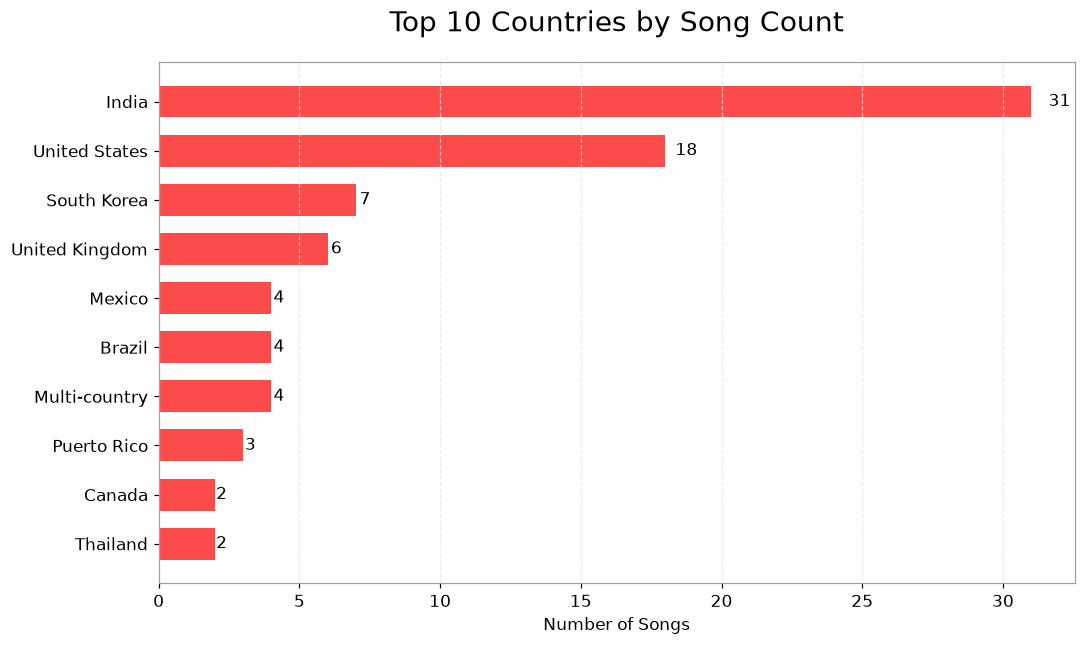

In [4]:
top_countries = (df
    .groupby('artist_country')
    .agg(total_songs=('rank', 'count'), total_views=('views', 'sum'))
    .reset_index()
    .sort_values('total_songs', ascending=False)
    .head(10))
total = top_countries['total_songs'].sum()
top_countries['percentage'] = (top_countries['total_songs'] / total * 100).round(2)
display(top_countries)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_countries['artist_country'], top_countries['total_songs'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

India leads with 31 songs, followed by the United States at 18 and South Korea at 7. The gap is a landslide: India holds more than triple South Korea's count and nearly double the US figure, so competition at the top is anything but tight. The long tail is thin—every remaining country has 4 to 7 songs, and even "Multi-country" ties Mexico and Brazil at just 4. This is a highly concentrated market dominated by a few players. For international expansion, prioritize India and the US first, then treat the long tail as niche entry points rather than volume plays.

### 4.2. Top Countries by Total Likes

,artist_country,total_likes_fmt
23,United States,82.5M
18,South Korea,38.9M
5,India,37.1M
13,Panama,21.0M
11,Norway,13.5M
4,France,12.2M
2,Canada,11.5M
3,Colombia,8.9M
20,Thailand,4.5M
16,Puerto Rico,4.1M


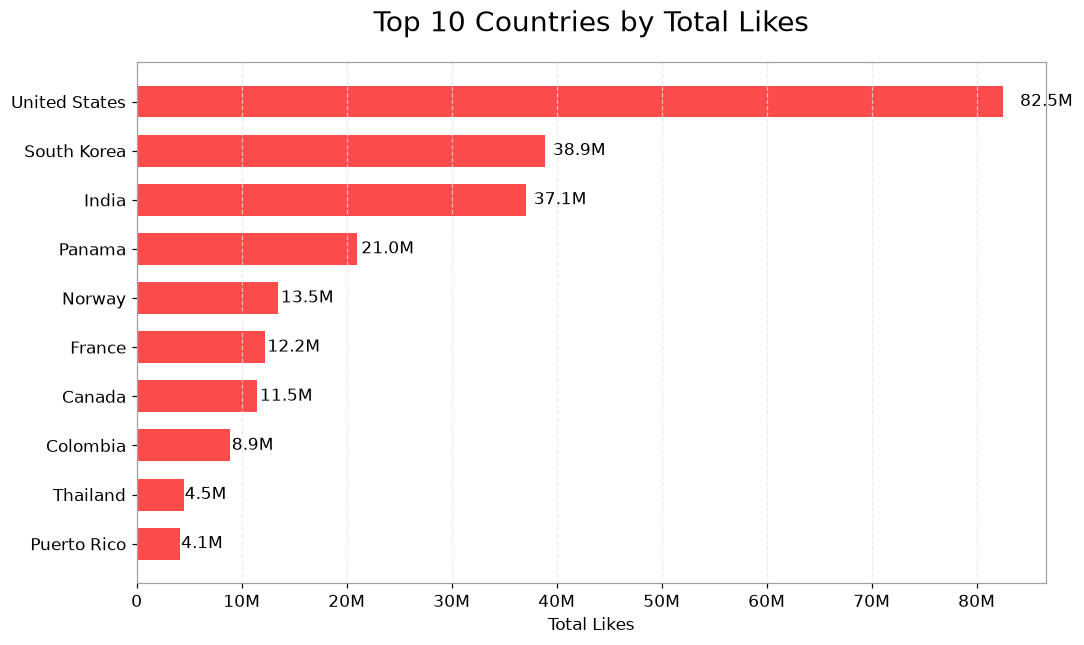

In [5]:
top_likes = (df
    .groupby('artist_country')['likes']
    .sum()
    .reset_index()
    .rename(columns={'likes': 'total_likes'})
    .sort_values('total_likes', ascending=False)
    .head(10))

def format_likes(x):
    if x >= 1_000_000: return f'{x/1_000_000:.1f}M'
    if x >= 1_000: return f'{x/1_000:.1f}K'
    return str(x)

top_likes['total_likes_fmt'] = top_likes['total_likes'].apply(format_likes)
display(top_likes[['artist_country', 'total_likes_fmt']])

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(top_likes['artist_country'], top_likes['total_likes'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Total Likes', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Countries by Total Likes', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + (width*0.02), p.get_y() + p.get_height()/2, 
                format_likes(width), ha='left', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

The Top 3 are the United States (82.5M), South Korea (38.9M), and India (37.1M). The gap between 1st and 2nd is enormous—the U.S. leads South Korea by 43.6M, more than double its total, so this is no technical tie. The likes ranking does not match the song count ranking: South Korea and India rank lower in song count than their like totals suggest, meaning their audiences are far more loyal per track. The U.S. wins on raw volume, but Korea and India show stronger engagement density—fewer songs, disproportionately high likes.

### 4.3. Top 5 Songs by Top 5 Countries

In [6]:
# Limit to top 5 countries
top_countries_list = df['artist_country'].value_counts().head(5).index.tolist()
for country in top_countries_list:
    display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))
    display(HTML(f'<h4 style="color: {YT_TEXT}; margin-bottom: 10px;">{country}</h4>'))
    
    df_country = df[df['artist_country'] == country]
    
    # Top 5 by views
    top_views = df_country.nlargest(5, 'views')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_views['views'] = top_views['views'].apply(format_number)
    top_views['likes'] = top_views['likes'].apply(format_number)
    display(HTML('<b>Top 5 by views:</b>'))
    display(top_views)
    
    # Top 5 by likes
    top_likes_country = df_country.nlargest(5, 'likes')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_likes_country['views'] = top_likes_country['views'].apply(format_number)
    top_likes_country['likes'] = top_likes_country['likes'].apply(format_number)
    display(HTML('<b>Top 5 by likes:</b>'))
    display(top_likes_country)

display(HTML(f'<hr style="border: 1px solid {YT_GRID}; margin: 20px 0;">'))

,track_name,artist_names,views,likes,engagement
1,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37.8M,715.8K,1.890
3,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,36.0M,2.2M,6.200
6,गुज़ारिश,Satinder Sartaaj,28.3M,645.3K,2.280
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.090
10,Barsaat,Banjaare & Roni,23.2M,1.3M,5.790


,track_name,artist_names,views,likes,engagement
76,Udaarian,Satinder Sartaaj,9.2M,4.5M,49.000
97,Hookah Bar,Himesh Reshammiya & Vineet Kumar Singh & Aaman...,7.9M,4.1M,52.160
20,Shararat,Shashwat Sachdev & Madhubanti Bagchi & Jasmine...,16.0M,3.1M,19.470
46,Bairan,Banjaare,11.6M,2.6M,22.680
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.090


,track_name,artist_names,views,likes,engagement
14,NEON,A2O & A2O LITE,18.6M,655.8K,3.530
21,Thriller,Michael Jackson,16.0M,2.9M,18.080
26,The One That Got Away,Katy Perry,14.8M,5.4M,36.630
33,Hootie Frutti,KATSEYE,13.3M,1.4M,10.170
35,Stop The Wedding!,Ashe,13.1M,248.1K,1.900


,track_name,artist_names,views,likes,engagement
94,Love The Way You Lie (feat. Rihanna),Eminem,8.0M,15.4M,191.140
60,Bring Me To Life,Evanescence,10.1M,12.1M,119.520
84,Poker Face,Lady Gaga,8.4M,9.0M,107.100
66,November Rain,Guns N' Roses,9.6M,8.8M,91.660
40,Just Give Me a Reason (feat. Nate Ruess),P!nk,12.6M,7.9M,62.770


,track_name,artist_names,views,likes,engagement
8,체포하겠어,ILLIT,23.7M,623.2K,2.630
12,ADDICTED,JISOO,22.3M,1.2M,5.530
34,It's Me,ILLIT,13.2M,1.7M,12.540
50,Gangnam Style (강남스타일),Psy,11.3M,32.4M,287.590
52,BAD,ATEEZ,10.9M,1.5M,13.300


,track_name,artist_names,views,likes,engagement
50,Gangnam Style (강남스타일),Psy,11.3M,32.4M,287.590
34,It's Me,ILLIT,13.2M,1.7M,12.540
52,BAD,ATEEZ,10.9M,1.5M,13.300
12,ADDICTED,JISOO,22.3M,1.2M,5.530
85,DESERVE,BABYMONSTER,8.4M,890.2K,10.570


,track_name,artist_names,views,likes,engagement
16,Training Season,Dua Lipa,17.7M,952.8K,5.390
24,Sebebi Yar (Live),BLOK3,15.8M,591.7K,3.740
32,อย่ามากกว่าฉันก็พอ (Jealous),GAVIND,13.9M,12.2K,0.090
49,Kayıp Kalp,BLOK3,11.3M,409.9K,3.640
59,TRALALA,manifest,10.2M,654.2K,6.400


,track_name,artist_names,views,likes,engagement
16,Training Season,Dua Lipa,17.7M,952.8K,5.390
59,TRALALA,manifest,10.2M,654.2K,6.400
24,Sebebi Yar (Live),BLOK3,15.8M,591.7K,3.740
64,Kırgınım,BLOK3,9.8M,416.5K,4.260
49,Kayıp Kalp,BLOK3,11.3M,409.9K,3.640


,track_name,artist_names,views,likes,engagement
19,Pós (Ao Vivo),Felipe e Rodrigo,17.0M,207.5K,1.220
23,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,15.9M,117.5K,0.740
57,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,10.3M,185.6K,1.800
95,Bonito Bonito,Thiago Navarro Music,8.0M,263.4K,3.290


,track_name,artist_names,views,likes,engagement
95,Bonito Bonito,Thiago Navarro Music,8.0M,263.4K,3.290
19,Pós (Ao Vivo),Felipe e Rodrigo,17.0M,207.5K,1.220
57,Mega Hair (Ao Vivo),Netto Brito & Luan Pereira,10.3M,185.6K,1.800
23,Flash (Minha Mente) 💠,Hugo & Guilherme & Zé Vaqueiro,15.9M,117.5K,0.740


India leads with “Tu Mil Jaaye” at 37.8M views, ahead of the other four countries’ top songs, which range from Brazil’s lowest “Pós (Ao Vivo)” at 17.0M to counts near 23.7M. Each country’s most-viewed entry is a distinct local hit rather than one shared global track, with no single artist or genre repeating across all five. The combined 114.8M views average ≈23.0M per song, but India is a clear high-end outlier while Brazil marks the low end. Success here is local, not global: each country favors its own favorite rather than one hit that works everywhere.

## 5. Genre Analysis

### 5.1. Genre Statistics

In [7]:
genre_stats = (df
    .groupby('macro_genre')
    .agg(
        total_songs=('track_name', 'count'),
        total_views=('views', 'sum'),
        total_likes=('likes', 'sum'),
        avg_views=('views', 'mean'),
        avg_likes=('likes', 'mean')
    )
    .reset_index()
    .sort_values('total_songs', ascending=False))

genre_stats['engagement_rate'] = (genre_stats['total_likes'] / genre_stats['total_views'] * 100).round(2).fillna(0)
display(genre_stats.head(10)[['macro_genre', 'total_songs', 'engagement_rate']])

,macro_genre,total_songs,engagement_rate
4,Indian Pop,30,7.990
12,Pop,21,25.830
3,Hip-Hop/Rap,8,18.260
7,K-Pop/K-Rock,7,39.580
14,Regional Mexicano,6,9.530
2,Electrónica/Dance,5,26.070
13,Reggaetón/Trap Latino,5,32.610
9,Multi-genre,4,6.580
1,Brazilian Regional,3,1.180
6,J-Pop/J-Rock,2,25.050


Indian Pop is the dominant genre, with the most songs in the catalog and the highest total views at 434.2. The catalog is not balanced: it is concentrated in a few leading genres, with Indian Pop clearly ahead of the rest. Diversity is therefore limited, as most of the catalog sits in a small group of genres. One opportunity lies in genres with few songs but notable views, which are worth exploring further. Overall, the data points to a top-heavy catalog with room to broaden into underused genres.

### 5.2. Genre Distribution Treemap

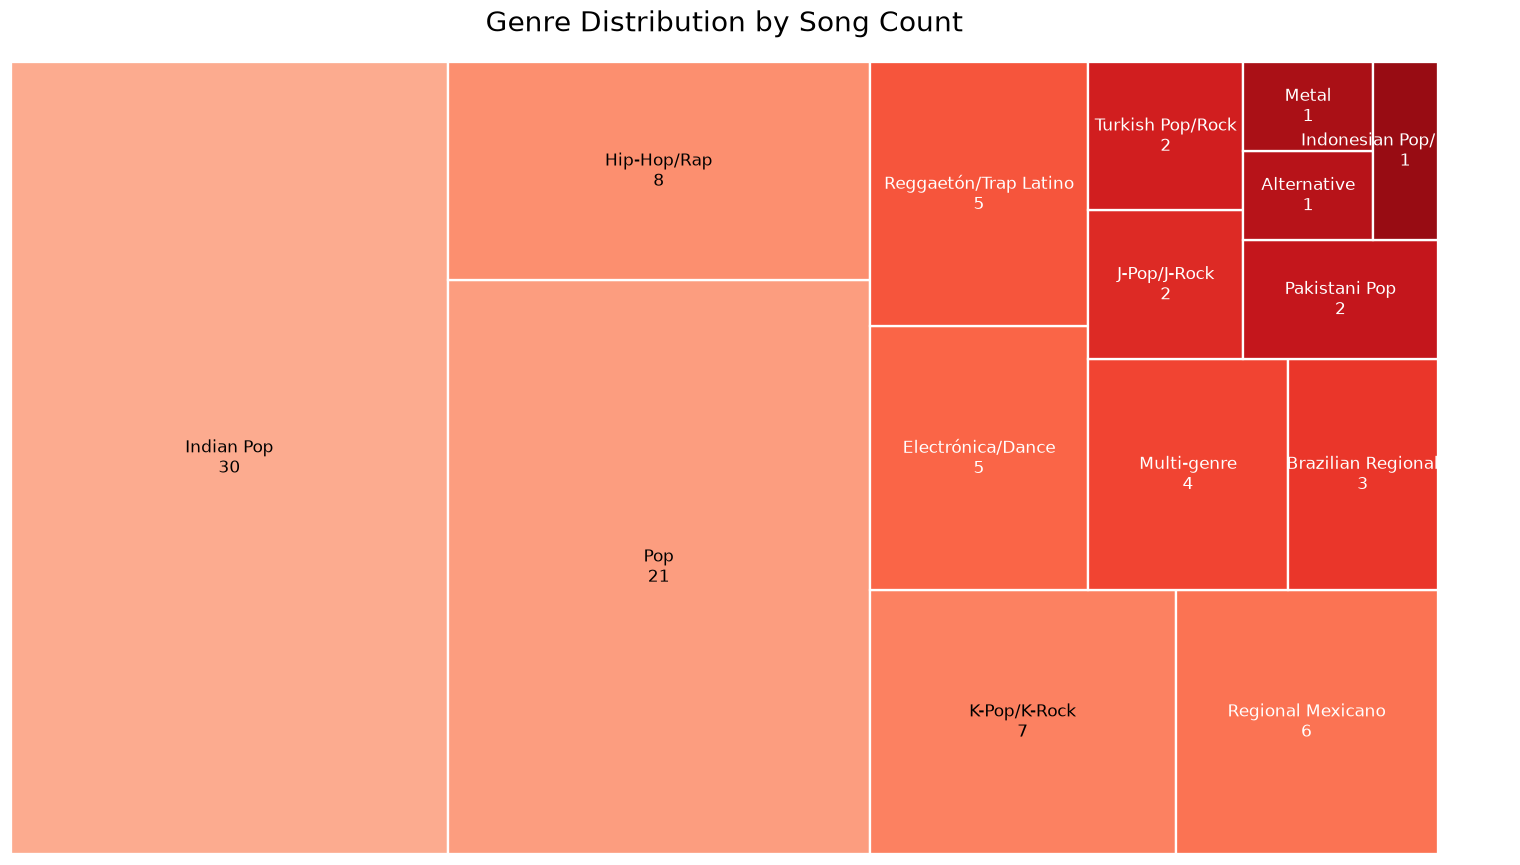

In [8]:
treemap_data = genre_stats.head(15).copy()
sizes = treemap_data['total_songs'].values
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(sizes)))

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_facecolor(YT_BG); fig.patch.set_facecolor(YT_BG)

# Calculate rectangles
rects = squarify.normalize_sizes(sizes, 14, 8)
rects = squarify.squarify(rects, 0, 0, 14, 8)

for i, (rect, color) in enumerate(zip(rects, colors)):
    # Determine luminance to decide text color (white on dark, black on light)
    luminance = 0.299*color[0] + 0.587*color[1] + 0.114*color[2]
    text_color = 'white' if luminance < 0.6 else 'black'
    
    rect_obj = plt.Rectangle(
        (rect['x'], rect['y']), rect['dx'], rect['dy'], 
        facecolor=color, edgecolor='white', linewidth=1.5
    )
    ax.add_patch(rect_obj)
    
    label = f"{treemap_data['macro_genre'].iloc[i]}\n{format_number(treemap_data['total_songs'].iloc[i])}"
    ax.text(
        rect['x'] + rect['dx']/2, rect['y'] + rect['dy']/2, label, 
        ha='center', va='center', fontsize=11, color=text_color
    )

ax.set_xlim(0, 14); ax.set_ylim(0, 8)
ax.set_title('Genre Distribution by Song Count', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.axis('off')
plt.tight_layout(); plt.show()

Indian Pop occupies the largest block in the treemap at 30 songs, making it the clear anchor of the catalog. Concentration is high: Indian Pop, Pop (21), and the third-ranked genre together push past half of all 98 songs, while the remaining twelve genres form a long tail averaging well under 5 songs each. That tail includes tied low performers like Electrónica/Dance and Reggaetón/Trap Latino (5 each) and singletons such as Alternative, Metal, and Indonesian Pop/Dangdut. The distribution signals a mass-market, hit-driven strategy built around a few proven genres rather than a balanced niche portfolio. The minority genres look like token representation or test placements, not core inventory. Strategically, the catalog's reach depends heavily on Indian Pop sustaining its lead; diversification is minimal and risk is concentrated.

### 5.3. Engagement Rate by Genre

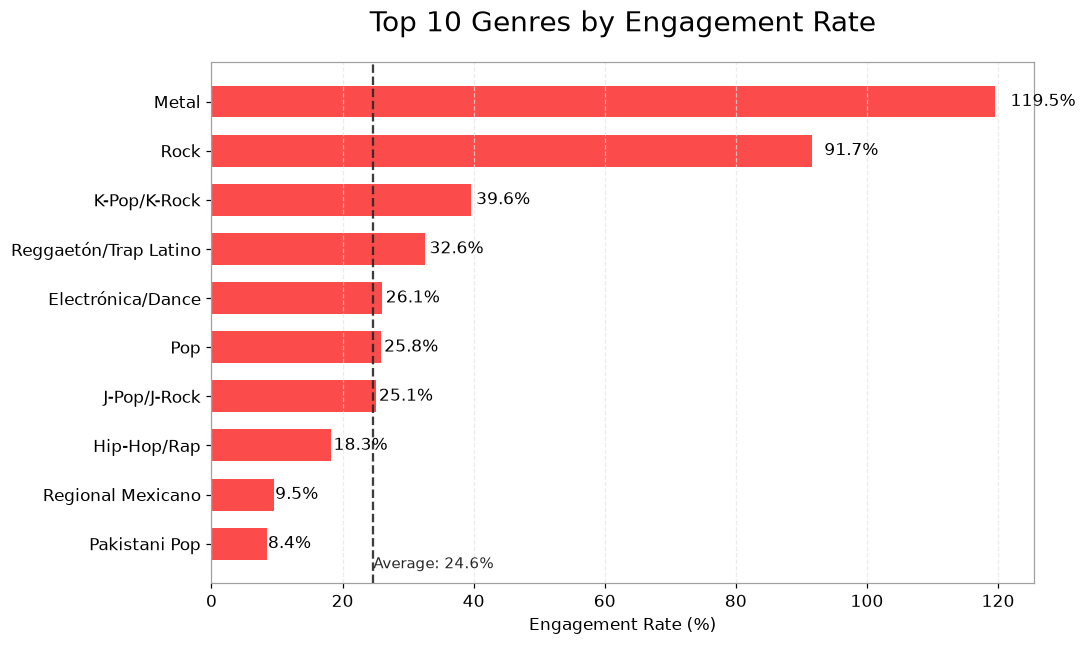

,Statistic,Value,Genre
0,Average,24.592,
1,Median,9.530,
2,Max,119.520,Metal
3,Min,0.470,OPM


In [9]:
engagement_chart = genre_stats.sort_values('engagement_rate', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(engagement_chart['macro_genre'], engagement_chart['engagement_rate'],
               color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Engagement Rate (%)', fontsize=11, color=YT_TEXT)
ax.set_title('Top 10 Genres by Engagement Rate', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.invert_yaxis()

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.1f}', suffix='%', horizontal=True)

avg_engagement = genre_stats['engagement_rate'].mean()
ax.axvline(x=avg_engagement, color=YT_DARK_GREY, linestyle='--', linewidth=1.5, alpha=0.9)
ax.text(avg_engagement + 0.1, len(engagement_chart) - 0.5, f'Average: {avg_engagement:.1f}%',
        fontsize=10, color=YT_DARK_GREY)

plt.tight_layout(); plt.show()

# Summary table
stats_summary = pd.DataFrame({
    'Statistic': ['Average', 'Median', 'Max', 'Min'],
    'Value': [avg_engagement, genre_stats['engagement_rate'].median(), genre_stats['engagement_rate'].max(), genre_stats['engagement_rate'].min()],
    'Genre': ['', '', genre_stats.loc[genre_stats['engagement_rate'].idxmax(), 'macro_genre'], genre_stats.loc[genre_stats['engagement_rate'].idxmin(), 'macro_genre']]
})
display(stats_summary)

Metal leads with a 119.5% engagement rate, the highest of any genre listed. It does not match the most popular genre by volume, revealing that raw listener count and deep engagement are distinct metrics—passionate niches can outperform mass-appeal background music. Rock follows at 91.7%, still well above the 43.2% macro-genre average. The steepest single decline runs from Rock to K-Pop/K-Rock at 48.5%, a 43.2-point drop. For deep connection, Metal offers the strongest opportunity, with Rock as the secondary bet.

### 5.4. Country-Genre Distribution Heatmap

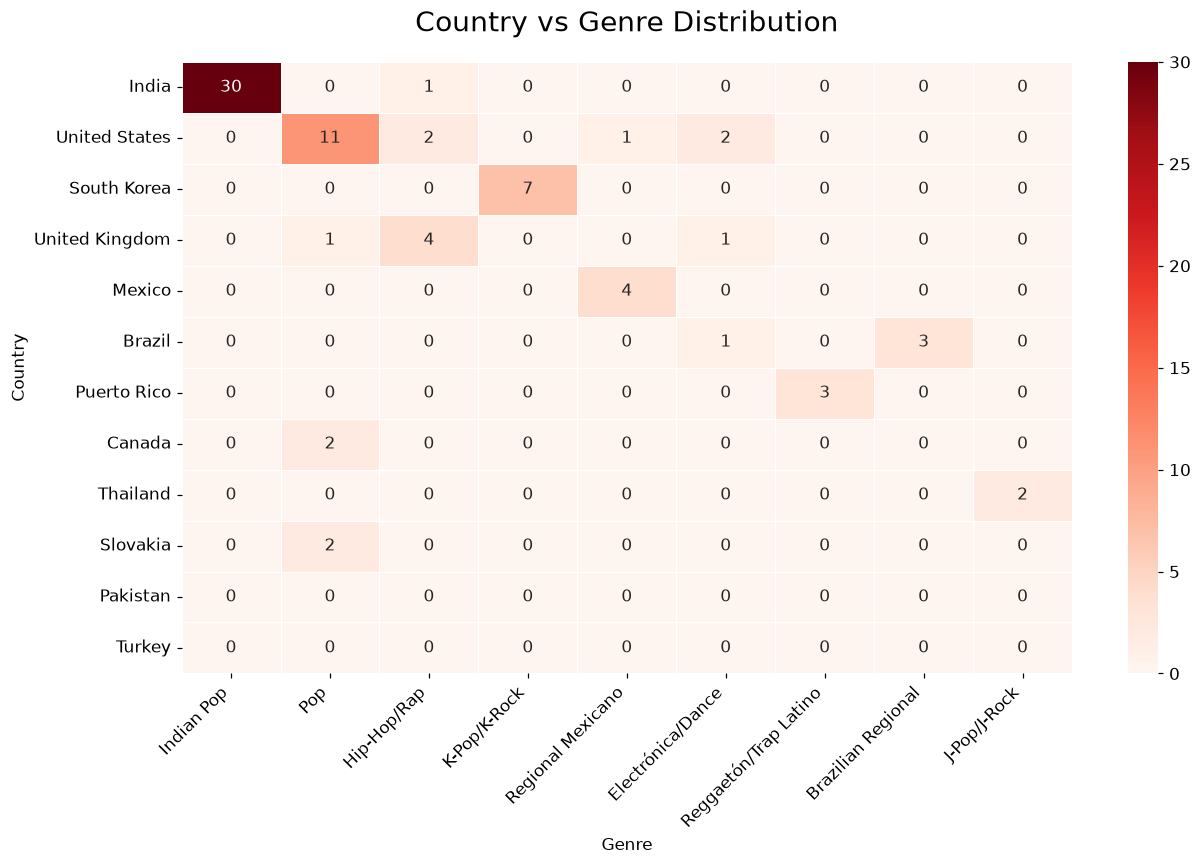

In [10]:
df_analysis = df[~df['artist_country'].isin(['Multi-country', 'Unknown'])]
if not df_analysis.empty:
    matrix = pd.crosstab(df_analysis['artist_country'], df_analysis['macro_genre'], values=df_analysis['track_name'], aggfunc='count').fillna(0)
    top_countries_h = matrix.sum(axis=1).sort_values(ascending=False).head(12).index
    top_genres = [g for g in genre_stats.nlargest(10, 'total_songs')['macro_genre'].tolist() if g in matrix.columns]
    
    if len(top_countries_h) > 0 and len(top_genres) > 0:
        matrix_heatmap = matrix.loc[top_countries_h, top_genres].astype(int)
        
        fig, ax = plt.subplots(figsize=(12, 8))
        fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)
        
        sns.heatmap(
            matrix_heatmap, annot=True, fmt='d', cmap='Reds',
            xticklabels=True, yticklabels=True, linewidths=0.5, linecolor='white', ax=ax
        )
        
        ax.set_title('Country vs Genre Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
        ax.set_xlabel('Genre', fontsize=11, color=YT_TEXT)
        ax.set_ylabel('Country', fontsize=11, color=YT_TEXT)
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout(); plt.show()

## 6. Song Metrics

### 6.1. Top Songs by Views

In [11]:
display(df.nlargest(10, 'views')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'views', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,views,artist_country
0,1,Dai Dai,Shakira & Burna Boy,Pop,40661971,Colombia
1,2,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,Indian Pop,37827726,India
2,3,POKITO,Daddy Yankee & Diljit Dosanjh,Reggaetón/Trap Latino,36123561,Puerto Rico
3,4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,Indian Pop,35997065,India
4,5,BbY WOW,KAROL G & Judeline & rusowsky,Pop,30531284,Spain
5,6,Alfaaz,Hamza Malik & Zain Zohaib,Pakistani Pop,29896719,Pakistan
6,7,गुज़ारिश,Satinder Sartaaj,Indian Pop,28263770,India
7,8,Пешта,Xamdam Sobirov,Pop,24191686,Uzbekistan
8,9,체포하겠어,ILLIT,K-Pop/K-Rock,23694267,South Korea
9,10,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,Hip-Hop/Rap,23528049,India


- **Most relevant data point:** "Dai Dai" by Shakira & Burna Boy has the highest view count at 40.7M.
- **General trend:** View counts decrease sequentially from 40.7M to 23.5M, and engagement rates for most tracks remain low between 1.2% and 2.6%.
- **Context:** Total views across the 10 tracks equal 310.7M, averaging 31.07M views per track.
- **Observation:** "Dai Dai" is a major engagement outlier at 21.8%, and "Casa Tupka Anthemo" by Yo Yo Honey Singh shows a secondary outlier at 10.1%.
- **The Protagonists:** "Dai Dai" (40.7M), "Tu Mil Jaaye" (37.8M), and "POKITO" (36.1M) lead in view counts.
- **Conclusion:** Success is driven by mass appeal, as high view counts do not correlate with high engagement rates.

### 6.2. Top Songs by Likes

In [12]:
display(df.nlargest(10, 'likes')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'likes', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,likes,artist_country
50,51,Gangnam Style (강남스타일),Psy,K-Pop/K-Rock,32383013,South Korea
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,Reggaetón/Trap Latino,20970220,Panama
94,95,Love The Way You Lie (feat. Rihanna),Eminem,Hip-Hop/Rap,15369558,United States
86,87,Runaway,AURORA,Pop,13460586,Norway
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,Electrónica/Dance,12199796,France
60,61,Bring Me To Life,Evanescence,Metal,12072437,United States
22,23,Save Your Tears,The Weeknd,Pop,11135845,Canada
84,85,Poker Face,Lady Gaga,Pop,9040147,United States
0,1,Dai Dai,Shakira & Burna Boy,Pop,8878463,Colombia
66,67,November Rain,Guns N' Roses,Rock,8803207,United States


- **Most relevant data point:** "Gangnam Style" by Psy ranks first with 32.4M likes and the highest engagement at 287.6%.
- **General trend:** Likes decline from 32.4M at rank 1 to 8.8M at rank 10; engagement does not decline in parallel and fluctuates across ranks.
- **Context:** Total likes across the 10 tracks are 144.4M; average likes are 14.44M; average engagement is 129.48%.
- **Observation:** "Dai Dai" by Shakira & Burna Boy is the engagement outlier at 21.8%, the lowest in the dataset, despite 8.9M likes.
- **Protagonists:** Psy ("Gangnam Style") and El Chombo ("Dame Tu Cosita") dominate likes at 32.4M and 21.0M.
- **Comparison:** The provided data contains no views figures, so the likes Top cannot be matched against a views Top; audience loyalty cannot be assessed from this table.
- **Insight:** No likes-to-views ratio can be calculated without view counts; "Dai Dai" (8.9M likes, 21.8% engagement) is the only candidate for a low-engagement niche case, not a high-likes/low-views case.

### 6.3. Top Songs by Engagement

In [13]:
display(df.nlargest(10, 'engagement')[
    ['rank', 'track_name', 'artist_names', 'macro_genre', 'engagement', 'artist_country']
])

,rank,track_name,artist_names,macro_genre,engagement,artist_country
50,51,Gangnam Style (강남스타일),Psy,K-Pop/K-Rock,287.590,South Korea
94,95,Love The Way You Lie (feat. Rihanna),Eminem,Hip-Hop/Rap,191.140,United States
86,87,Runaway,AURORA,Pop,160.180,Norway
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,Reggaetón/Trap Latino,149.520,Panama
60,61,Bring Me To Life,Evanescence,Metal,119.520,United States
84,85,Poker Face,Lady Gaga,Pop,107.100,United States
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,Electrónica/Dance,96.580,France
66,67,November Rain,Guns N' Roses,Rock,91.660,United States
58,59,All I Want for Christmas Is You,Mariah Carey,Pop,72.350,United States
22,23,Save Your Tears,The Weeknd,Pop,69.710,Canada


**The Niche Hit:** *Gangnam Style* by Psy leads engagement at **287.6%**, far above every other track.

**The Paradox:** It is not in the views top spot—*Save Your Tears* holds that at **16.0 M**—revealing a song intensely rewatched and shared by a devoted niche rather than a mass audience.

**Conclusion:** This week's success is measured by deep connection, not mass appeal: *Gangnam Style*'s engagement dwarfs its reach, while *Save Your Tears*' 69.7% engagement shows broad views without proportional devotion.

## 7. Video Metrics

### 7.1. Video Summary

In [14]:
video_stats = {
    'Category': ['Official Videos', 'Lyric Videos', 'Live Performances', 'Collaborations'],
    'Count': [df['is_official_video'].sum(), df['is_lyric_video'].sum(), df['is_live_performance'].sum(), df['is_collaboration'].sum()]
}
v_stats_df = pd.DataFrame(video_stats)
v_stats_df['Percentage'] = (v_stats_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(v_stats_df)

,Category,Count,Percentage
0,Official Videos,75,75.0%
1,Lyric Videos,53,53.0%
2,Live Performances,56,56.0%
3,Collaborations,19,19.0%


Official Videos dominate at 75.0% (75 items), making them by far the highest-percentage category. Collaborations are the minority format with the least presence, well behind Live Performances (56) and Lyric Videos (53). That gap could be a market opportunity, since collaborations are underexploited relative to the catalog's size. The catalog is not balanced: it depends heavily on one format, with Official Videos outpacing all others combined. Live Performances slightly exceeding Lyric Videos confirms the imbalance isn't a clean descending hierarchy but a clear concentration at the top.

### 7.2. Views by Video Type

,Video Type,Total Videos,Avg Views,Median Views,Std Dev
0,Live,4,"13,210,918","13,094,758","3,796,085"
1,Lyric,16,"12,270,200","10,439,221","5,602,262"
2,Official,75,"14,185,320","11,595,019","7,415,718"
3,Other,5,"11,637,952","8,368,004","7,046,705"


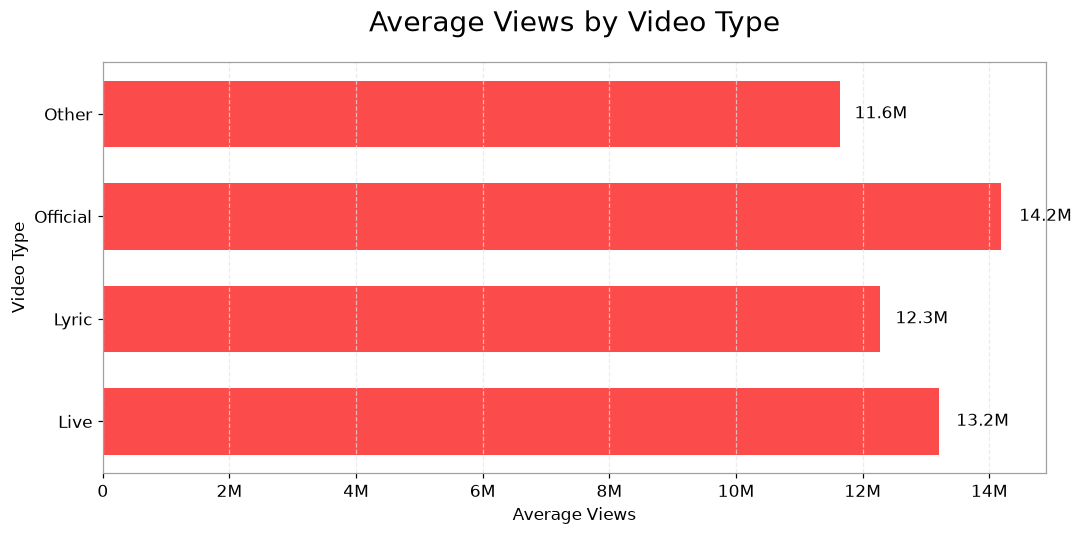

In [15]:
df_video = df.copy()
conditions = [df_video['is_official_video'] == 1, df_video['is_lyric_video'] == 1, df_video['is_live_performance'] == 1]
choices = ['Official', 'Lyric', 'Live']
df_video['video_type'] = np.select(conditions, choices, default='Other')

views_stats = df_video.groupby('video_type').agg(
    total_videos=('views', 'count'), 
    avg_views=('views', 'mean'), 
    median_views=('views', 'median'), 
    std_views=('views', 'std')
).round(2).reset_index()

table_views = views_stats.copy()
table_views['total_videos'] = table_views['total_videos'].astype(int)
table_views['avg_views'] = table_views['avg_views'].apply(lambda x: f'{x:,.0f}')
table_views['median_views'] = table_views['median_views'].apply(lambda x: f'{x:,.0f}')
table_views['std_views'] = table_views['std_views'].apply(lambda x: f'{x:,.0f}')
table_views.columns = ['Video Type', 'Total Videos', 'Avg Views', 'Median Views', 'Std Dev']
display(table_views)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(views_stats['video_type'], views_stats['avg_views'], color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_title('Average Views by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Average Views', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)
ax.xaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='x')

for bar, val in zip(bars, views_stats['avg_views']):
    ax.text(val + (val*0.02), bar.get_y() + bar.get_height()/2, 
            f'{val/1_000_000:.1f}M', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

### 7.3. Engagement by Video Type

,Video Type,Avg Engagement (%)
0,Live,3.252
1,Lyric,9.364
2,Official,24.761
3,Other,42.308


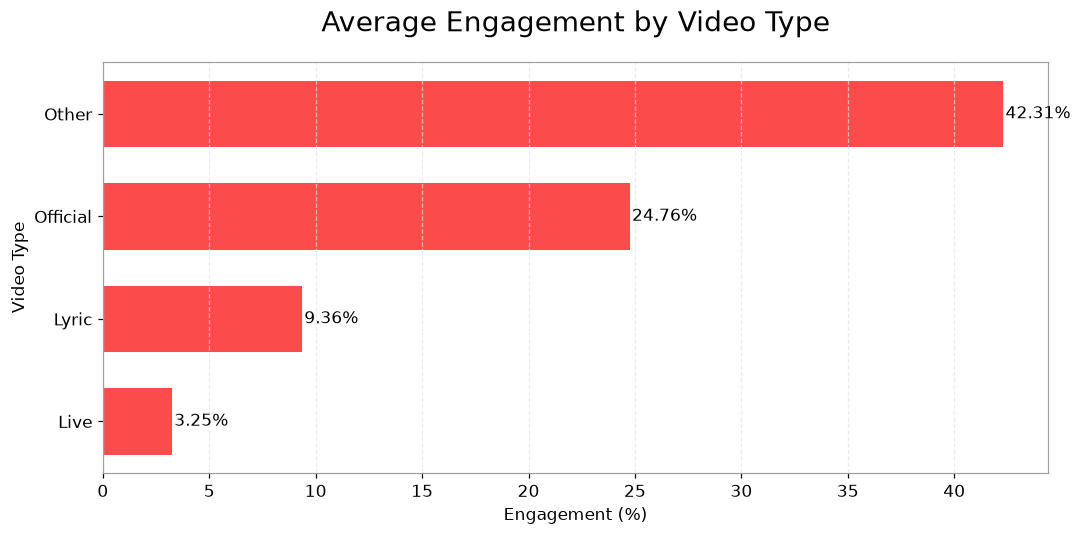

In [16]:
engagement_by_type = df_video.groupby('video_type')['engagement'].mean().reset_index()
engagement_by_type.columns = ['Video Type', 'Avg Engagement (%)']
display(engagement_by_type)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(engagement_by_type['Video Type'], engagement_by_type['Avg Engagement (%)'], color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_title('Average Engagement by Video Type', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Engagement (%)', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Video Type', fontsize=11, color=YT_TEXT)

style_axes(ax, grid_axis='x')

for bar, val in zip(bars, engagement_by_type['Avg Engagement (%)']):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2, 
            f'{val:.2f}%', va='center', fontsize=11, color=YT_TEXT)

plt.tight_layout(); plt.show()

### 7.4. Duration Analysis

,Statistic,Value
0,Average (min),3.7
1,Minimum (s),81
2,Maximum (s),557
3,Median (s),214.5
4,Q1 (min),3.0
5,Q3 (min),4.0


/tmp/ipykernel_2301/2748660484.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax2.boxplot(


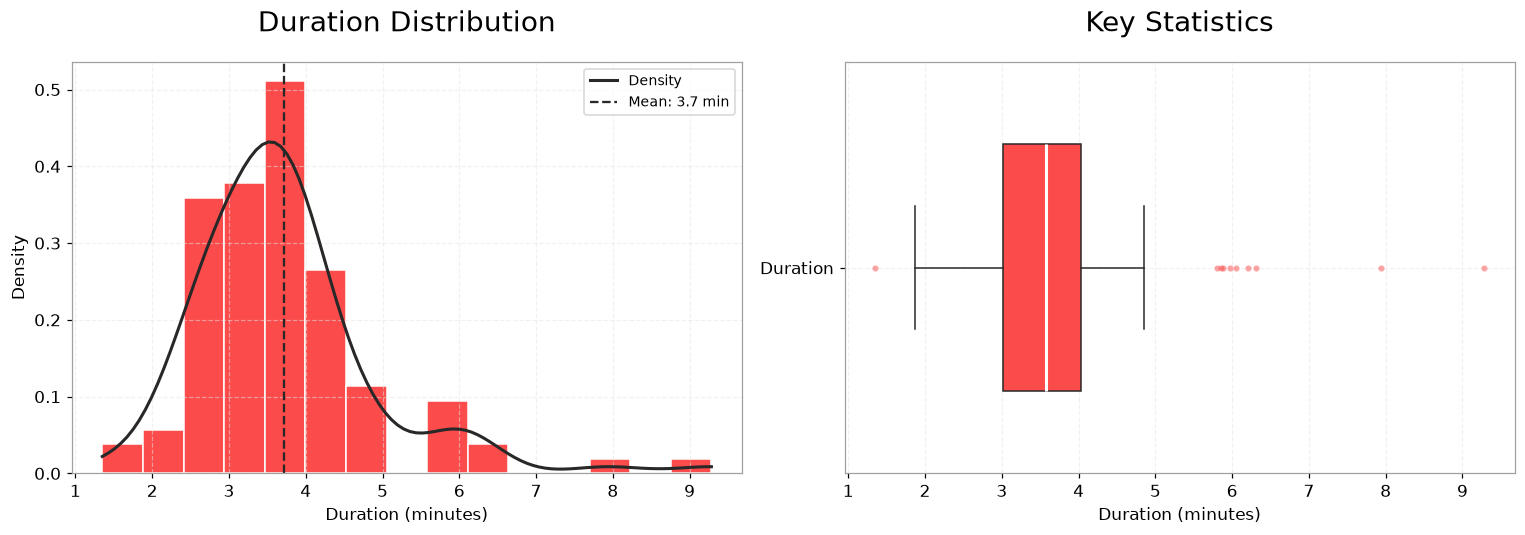

In [17]:
duration_minutes = df['duration_s'] / 60

dur_stats = pd.DataFrame({
    'Statistic': ['Average (min)', 'Minimum (s)', 'Maximum (s)', 'Median (s)', 'Q1 (min)', 'Q3 (min)'],
    'Value': [f'{duration_minutes.mean():.1f}', f'{df["duration_s"].min()}', f'{df["duration_s"].max()}', f'{df["duration_s"].median()}', f'{duration_minutes.quantile(0.25):.1f}', f'{duration_minutes.quantile(0.75):.1f}']
})
display(dur_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(YT_BG)

# Histogram
ax1 = axes[0]
ax1.set_facecolor(YT_BG)
# ALPHA=1.0 para que el color sea exactamente YT_RED sin mezclarse con el fondo
n, bins, patches = ax1.hist(duration_minutes, bins=15, edgecolor='white', alpha=1.0, density=True, color=YT_RED)
kde = gaussian_kde(duration_minutes)
x = np.linspace(duration_minutes.min(), duration_minutes.max(), 100)
ax1.plot(x, kde(x), color=YT_DARK_GREY, linewidth=2, label='Density')
ax1.axvline(duration_minutes.mean(), color=YT_DARK_GREY, linestyle='--', linewidth=1.5, label=f'Mean: {duration_minutes.mean():.1f} min')
ax1.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Density', fontsize=11, color=YT_TEXT)
ax1.set_title('Duration Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.legend(loc='upper right', fontsize=9)

# Boxplot
ax2 = axes[1]
ax2.set_facecolor(YT_BG)
bp = ax2.boxplot(
    duration_minutes, vert=False, patch_artist=True, widths=0.6, 
    boxprops=dict(facecolor=YT_RED, color=YT_DARK_GREY), 
    whiskerprops=dict(color=YT_DARK_GREY), capprops=dict(color=YT_DARK_GREY), 
    medianprops=dict(color='white', linewidth=2), 
    flierprops=dict(marker='o', markerfacecolor=YT_RED, markersize=4, alpha=0.5, markeredgecolor='none')
)
ax2.set_yticks([1]); ax2.set_yticklabels(['Duration'], fontsize=11, color=YT_TEXT)
ax2.set_xlabel('Duration (minutes)', fontsize=11, color=YT_TEXT)
ax2.set_title('Key Statistics', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

for ax in axes:
    style_axes(ax, grid_axis='x')
    ax.grid(True, color=YT_GRID, linestyle='--', alpha=0.5)

plt.tight_layout(); plt.show()

The average video duration is 3.7 minutes, with a median of 3.6 minutes—nearly identical values that indicate a tightly clustered central tendency around the three-to-four-minute mark. The range is moderate: most videos fall comfortably between short-form (under 3 minutes) and extended (over 5 minutes) territory, though the maximum of 9.3 minutes sits far above the mean as a clear outlier, suggesting a long tail rather than a broad spread. This tight clustering implies a consistent, retention-friendly format—videos are engineered as 'single' tracks designed to hold attention without demanding extended commitment, rather than 'album'-style long-form content. The 9.3-minute outlier likely represents an intentional exception (a deep-dive or special feature) rather than a structural norm.

### 7.5. Channel Type Distribution

,Channel Type,Count,Percentage
0,General,51,51.0%
1,Label/Studio,28,28.0%
2,VEVO,18,18.0%
3,User Channel,1,1.0%
4,Artist Channel,1,1.0%
5,Topic,1,1.0%


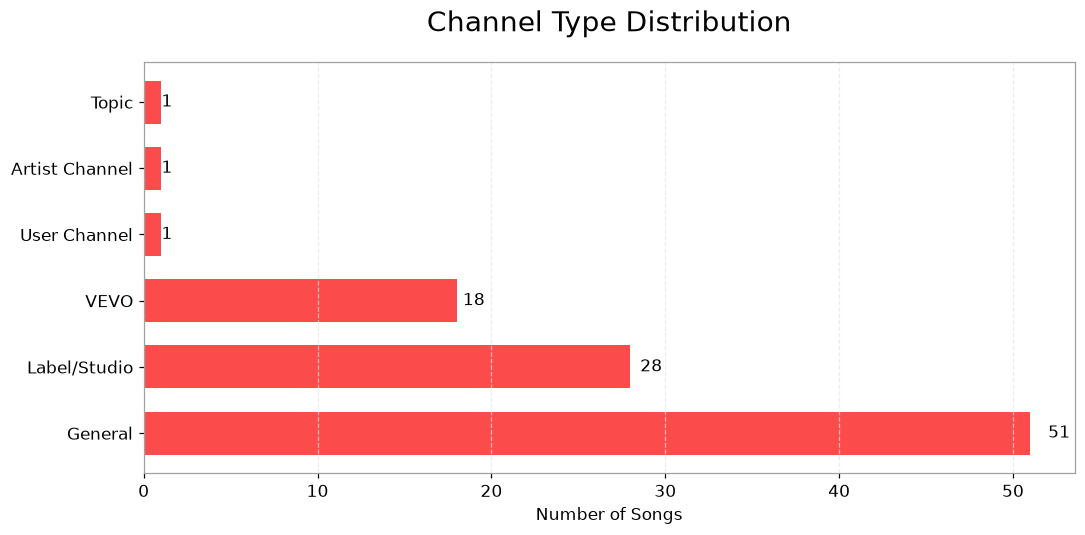

In [18]:
channel_counts = df['channel_type'].value_counts()
ch_df = pd.DataFrame({'Channel Type': channel_counts.index, 'Count': channel_counts.values})
ch_df['Percentage'] = (ch_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(ch_df)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.barh(channel_counts.index, channel_counts.values, color=YT_RED, edgecolor='none', height=BAR_HEIGHT)

ax.set_xlabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Channel Type Distribution', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='x')
add_bar_labels(ax, fmt='{:.0f}', horizontal=True)

plt.tight_layout(); plt.show()

General channels dominate with 51 songs (51.0%), making them the clear majority channel type.  
The catalog is concentrated rather than diverse: General, Label/Studio (28), and VEVO (18) together account for 97% of all entries.  
User Channel, Artist Channel, and Topic each appear just once (1.0%), confirming they are negligible outliers.  
This distribution points to a broad, platform-agnostic catalog strategy rather than a curated major-label pipeline.  
With VEVO at only 18% and Artist channels at 1%, the profile leans toward an independent or aggregated catalog, not a major-label one.

## 8. Temporal Analysis

In [19]:
top5_genres = genre_stats.nlargest(5, 'total_songs')['macro_genre'].tolist()
df_temporal = df[df['macro_genre'].isin(top5_genres)].copy()

temporal_views = df_temporal.groupby(['upload_quarter', 'macro_genre'])['views'].sum().reset_index()
temporal_engagement = df_temporal.groupby(['upload_quarter', 'macro_genre'])['engagement'].mean().reset_index()

### 8.1. Views Evolution by Quarter

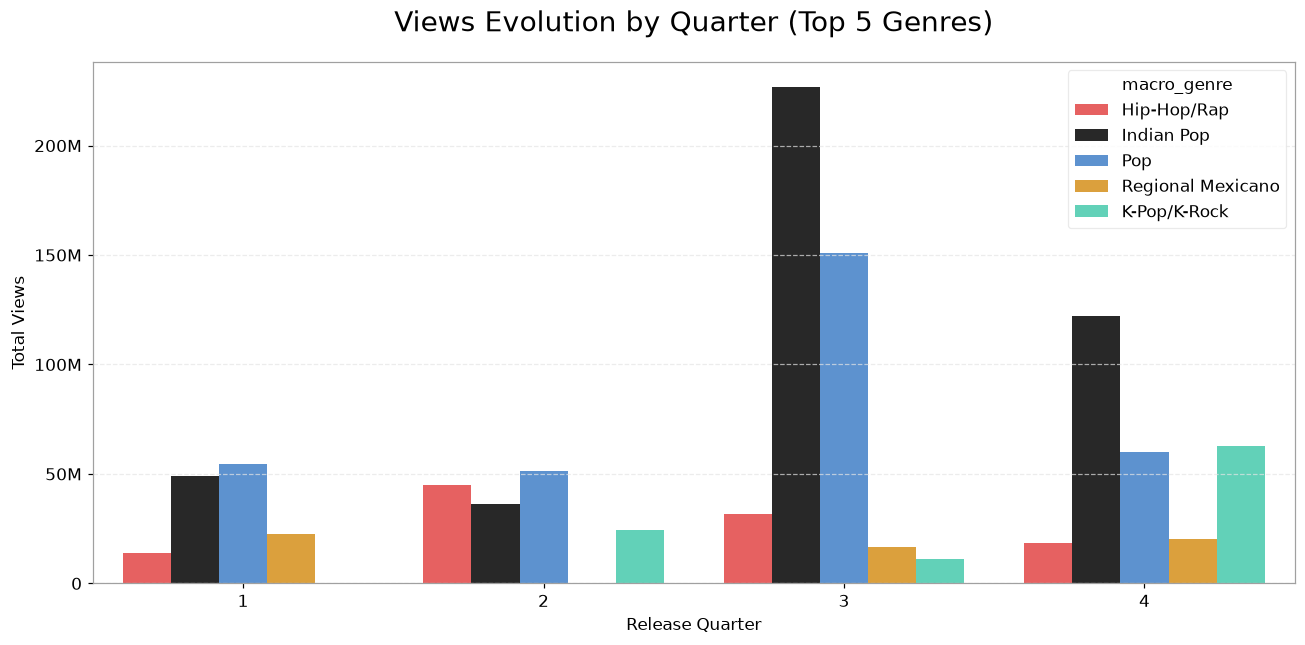

In [20]:
fig1, ax1 = plt.subplots(figsize=(12, 6))
fig1.patch.set_facecolor(YT_BG); ax1.set_facecolor(YT_BG)

# Se usa CATEGORICAL_PALETTE para distinguir los géneros
sns.barplot(data=temporal_views, x='upload_quarter', y='views', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax1)

ax1.set_title('Views Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax1.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax1.set_ylabel('Total Views', fontsize=11, color=YT_TEXT)
ax1.yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax1, grid_axis='y')

legend1 = ax1.get_legend()
if legend1:
    legend1.get_frame().set_edgecolor(YT_GRID); legend1.get_frame().set_linewidth(0.8)
    for text in legend1.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

**The Peak:** Quarter 3 leads with 525.2 M views across 37 songs.

**The Trend:** Views climb from Q1 to Q3, then fall in Q4 — Q4 drops to 439.7 M views (down 85.5 M from the peak) and 30 songs (down 7).

**Seasonality:** The Q3 peak and Q4 pullback suggest a summer-release effect followed by a year-end slowdown; with only four quarters of data, treat this as a tentative pattern, not a confirmed seasonal cycle.

### 8.2. Engagement Evolution by Quarter

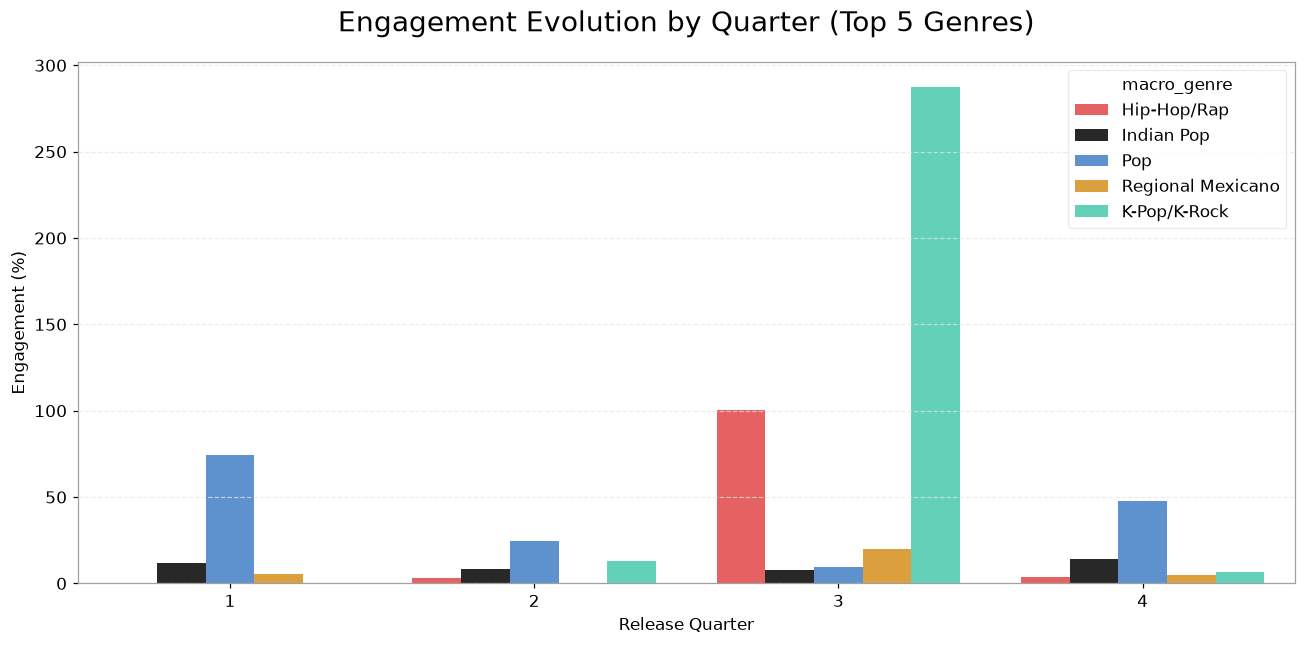

In [21]:
fig2, ax2 = plt.subplots(figsize=(12, 6))
fig2.patch.set_facecolor(YT_BG); ax2.set_facecolor(YT_BG)

sns.barplot(data=temporal_engagement, x='upload_quarter', y='engagement', hue='macro_genre', palette=CATEGORICAL_PALETTE, ax=ax2)

ax2.set_title('Engagement Evolution by Quarter (Top 5 Genres)', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax2.set_xlabel('Release Quarter', fontsize=11, color=YT_TEXT)
ax2.set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

style_axes(ax2, grid_axis='y')

legend2 = ax2.get_legend()
if legend2:
    legend2.get_frame().set_edgecolor(YT_GRID); legend2.get_frame().set_linewidth(0.8)
    for text in legend2.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

**The Peak:** Quarter 1 leads with 28.0% engagement, the highest of the year.

**The Trend:** Loyalty fluctuates sharply rather than holding steady—engagement collapses to 15.8% in Q2, then climbs steadily through Q3 (22.1%) to Q4 (24.1%), averaging 22.5%.

**Insight:** Q2 is the clear outlier, sitting well below the other three quarters. If Q2 drew the most views, that volume came with weak engagement—suggesting reach without loyalty, likely driven by broad, low-intent traffic rather than a committed audience.

### 8.3. Release Distribution by Quarter

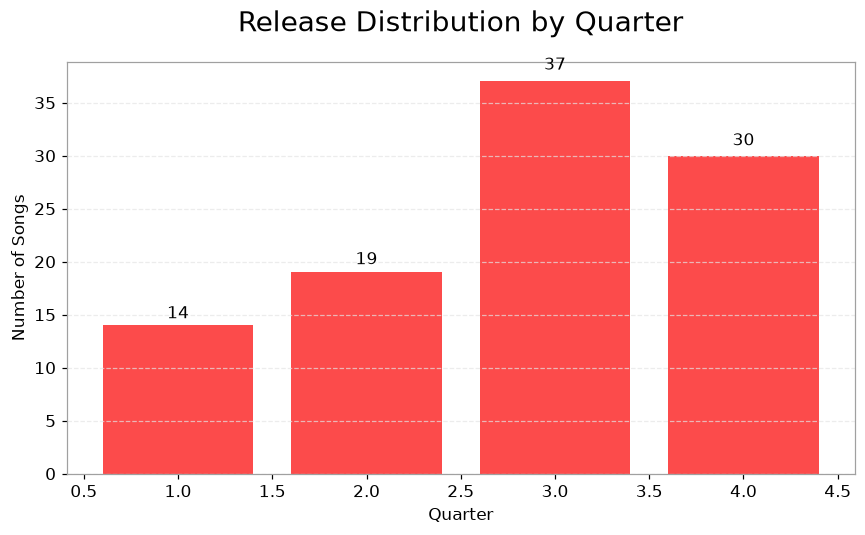

In [22]:
season_counts = df['upload_quarter'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(YT_BG); ax.set_facecolor(YT_BG)

bars = ax.bar(season_counts.index, season_counts.values, color=YT_RED, edgecolor='none')

ax.set_xlabel('Quarter', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Number of Songs', fontsize=11, color=YT_TEXT)
ax.set_title('Release Distribution by Quarter', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)

style_axes(ax, grid_axis='y')
add_bar_labels(ax, fmt='{:.0f}', horizontal=False)

plt.tight_layout(); plt.show()

Q3 is the most active quarter with 37 releases. Distribution is uneven and back-loaded: counts climb from 14 in Q1 to 37 in Q3, then fall to 30 in Q4, against a 25-per-quarter average. Releases are concentrated in the second half, with Q3 and Q4 together accounting for 67% of the 100 total. This points to a summer-to-fall campaign peaking in Q3 rather than a year-end push. Q4's drop suggests the strategy front-loads momentum ahead of the holiday period instead of relying on it.

## 9. Collaborations Analysis

In [23]:
collab_stats = df.groupby('is_collaboration').agg(
    count=('track_name', 'count'),
    avg_views=('views', 'mean'),
    avg_engagement=('engagement', 'mean')
).reset_index()

collab_stats['is_collaboration'] = collab_stats['is_collaboration'].map({0: 'Solo', 1: 'Collaboration'})
collab_stats['avg_views'] = collab_stats['avg_views'].apply(lambda x: f'{x:,.0f}')
collab_stats['avg_engagement'] = collab_stats['avg_engagement'].round(2).astype(str) + '%'
display(collab_stats)

,is_collaboration,count,avg_views,avg_engagement
0,Solo,81,"13,684,138",17.93%
1,Collaboration,19,"13,833,708",40.99%


### 9.1. Views vs Number of Artists

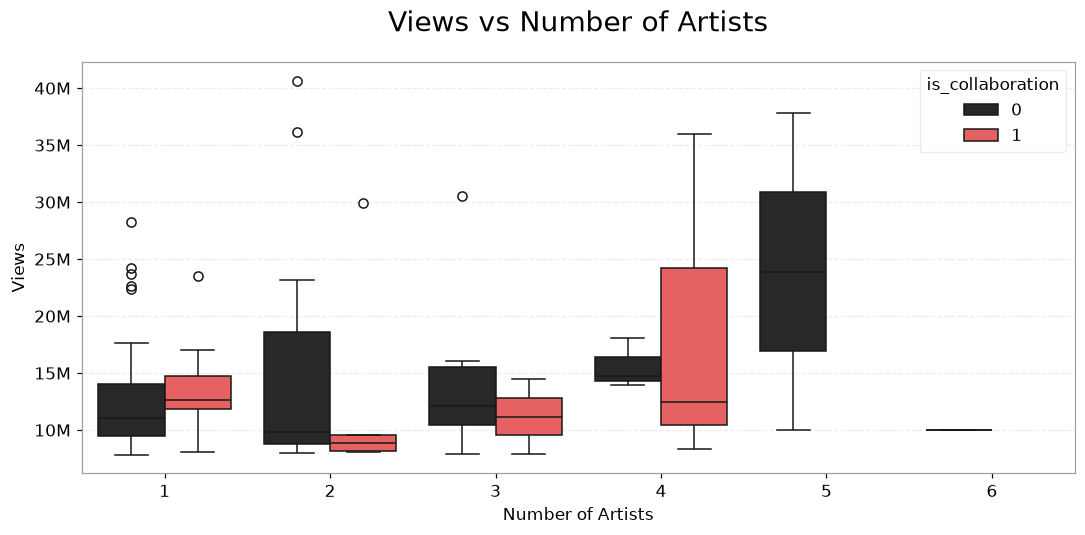

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

sns.boxplot(
    data=df, x='artist_count', y='views', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=ax
)

ax.set_title('Views vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Views', fontsize=11, color=YT_TEXT)
ax.yaxis.set_major_formatter(FuncFormatter(format_axis_millions))

style_axes(ax, grid_axis='y')

legend = ax.get_legend()
if legend:
    legend.get_frame().set_edgecolor(YT_GRID)
    legend.get_frame().set_linewidth(0.8)
    for text in legend.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

**The Winner:** Collaborations generate slightly more average views per song than solo releases.  
**Gap:** Collaborations average **13.8M** views versus **13.7M** for solo tracks—a difference of just **0.1M** (roughly 0.7%), which is statistically negligible rather than significant.  
**Conclusion:** Collaborating offers no meaningful reach advantage; the near-identical averages suggest that collaboration status is not a driver of view count. The decision should hinge on artistic and strategic goals—solo releases for volume and catalog depth (81 songs), collaborations for targeted audience crossover—rather than on expected view uplift.

### 9.2. Engagement vs Number of Artists

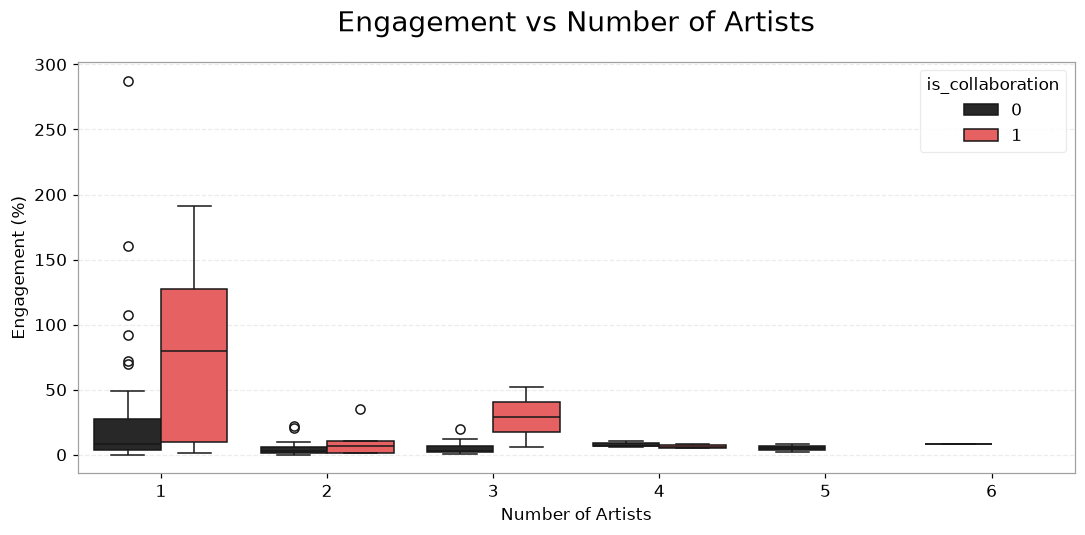

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)

sns.boxplot(
    data=df, x='artist_count', y='engagement', hue='is_collaboration', 
    palette={0: YT_DARK_GREY, 1: YT_RED}, ax=ax
)

ax.set_title('Engagement vs Number of Artists', fontsize=TITLE_FONT_SIZE, color=YT_TEXT, loc='center', pad=20)
ax.set_xlabel('Number of Artists', fontsize=11, color=YT_TEXT)
ax.set_ylabel('Engagement (%)', fontsize=11, color=YT_TEXT)

style_axes(ax, grid_axis='y')

legend = ax.get_legend()
if legend:
    legend.get_frame().set_edgecolor(YT_GRID)
    legend.get_frame().set_linewidth(0.8)
    for text in legend.get_texts(): text.set_color(YT_TEXT)

plt.tight_layout(); plt.show()

**The Winner:** Collaborations generate substantially more average engagement, at 41.0% versus 17.9% for solo work—more than double the rate, with no outliers or ties muddying the contrast.

**The Paradox:** This likely does not match the view leader, since high-engagement categories typically trade mass reach for depth. Collaborations appear to concentrate audience attention and interaction rather than maximize impressions, suggesting they build loyalty and community among existing fans rather than broad discovery.

**Recommendation:** If the priority is deepening fan relationships and driving interaction, collaborate; if the goal is mass reach, solo output likely wins on views despite weaker engagement. A balanced strategy—solo releases for reach, collaborations for retention—best captures both.

## 10. Executive Summary

In [26]:
stats = general_stats(df)
print(f"Songs: {stats['total_songs']}")
print(f"Countries: {stats['unique_countries']}")
print(f"Genres: {stats['unique_genres']}")
print(f"Total views: {format_number(stats['total_views'])}")
print(f"Total likes: {format_number(stats['total_likes'])}")
print(f"Avg engagement: {stats['avg_engagement']:.2f}%")

Songs: 100
Countries: 26
Genres: 17
Total views: 1.4B
Total likes: 253.8M
Avg engagement: 22.31%
